In [1]:
%run ./dataManipulation.ipynb

In [2]:
import seaborn as sns
from scipy import stats

from tensorflow.keras.utils import to_categorical
from sklearn.preprocessing import LabelEncoder

from sklearn.model_selection import StratifiedGroupKFold, GroupShuffleSplit, GridSearchCV
from sklearn.metrics import f1_score, confusion_matrix, accuracy_score, recall_score, precision_score, precision_recall_curve
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

2024-03-17 22:17:56.816852: I tensorflow/core/platform/cpu_feature_guard.cc:182] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F AVX512_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


In [3]:
columns = ['clipID', 'Extraversion', 'Agreeableness', 'Conscientiousness', 'Neuroticism', 'Openness', 'Gender']
listOfGenders = np.array(metadata)[:,2]
unique_values, counts = np.unique(listOfGenders, return_counts=True)

In [14]:
labelencoder=LabelEncoder()
y=to_categorical(labelencoder.fit_transform(listOfGenders))[:,0].astype(int)
# No of men vs no of women

valueCounts = pd.DataFrame(y).value_counts().reset_index()
valueCounts.columns = ['Value', 'Frequency']
valueCounts = valueCounts.rename(index={0: 'Male', 1: 'Female'})
totalClips = valueCounts['Frequency'].sum()
valueCounts['Percentage'] = (valueCounts['Frequency'] / totalClips) * 100
display(Markdown('## Class Imbalance'))
display(valueCounts)


array = np.concatenate((medianScoresPerClip(), listOfGenders.reshape(-1,1)), axis=1)
df = pd.DataFrame(array, columns=columns)
dfMale = df[df.Gender == 'M']
dfFemale = df[df.Gender == 'F']
df = pd.concat([dfMale, dfFemale])
plt.figure(figsize=(4, 4))
sns.countplot(x='Gender', data=df, hue=['lightblue', 'darkblue'])
plt.gca().spines['top'].set_visible(False)
plt.gca().spines['right'].set_visible(False)
plt.title('Frequency of Female vs Male Classes')
plt.xlabel('Gender')
plt.ylabel('Frequency')
plt.show()




## Class Imbalance

,Value,Frequency,Percentage
Male,0,503,78.59375
Female,1,137,21.40625


ValueError: Length of list vectors must match length of `data` when both are used, but `data` has length 640 and the vector passed to `hue` has length 2.

<Figure size 400x400 with 0 Axes>

## PCA

Pricipal component variance: [0.35845079 0.29290806]


'Relationship between original features (Big Five) and Principal Components:'

,PC1,PC2
Extraversion,0.602524,-0.157927
Agreeableness,-0.371915,-0.584500
Conscientiousness,0.370081,-0.533504
Neuroticism,0.487827,0.439006
Openness,0.351723,-0.395052


Amount of variance per principal component: [0.35845079 0.29290806 0.15350095 0.10301126 0.09212895]


<Figure size 640x480 with 0 Axes>

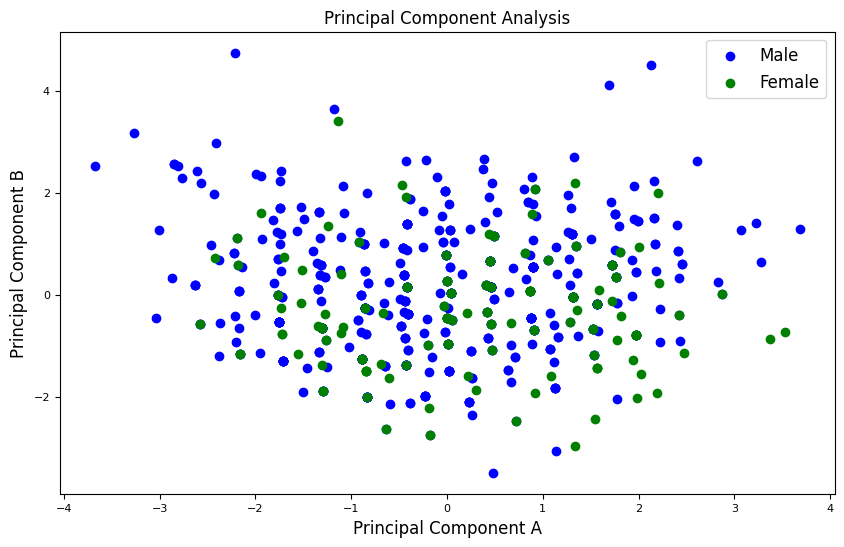

In [5]:
data = medianScoresPerClip()[:,1:]

labels = np.reshape(y, (640,1))
finalData = np.concatenate([data, labels], axis=1)
finalDataset = pd.DataFrame(finalData)
finalDataset.columns = columns[1:]
finalDataset['Gender'].replace(0, 'Male',inplace=True)
finalDataset['Gender'].replace(1, 'Female',inplace=True)

x = finalDataset.loc[:, columns[1:6]].values
x = StandardScaler().fit_transform(x)

normalised = pd.DataFrame(x, columns=bigFive)

pca = PCA(n_components=2)
princComp = pca.fit_transform(x)
pcaDf = pd.DataFrame(data = princComp, columns = ['principal component 1', 'principal component 2'])

# VARIANCE OF THE DATASET DEFINED BY EACH COMPONENT OF THE TWO
print('Pricipal component variance: {}'.format(pca.explained_variance_ratio_))

# Relationship between original features (Big Five) and Principal Components
loadings = pd.DataFrame(pca.components_.T, columns=['PC1', 'PC2'], index=bigFive)
display("Relationship between original features (Big Five) and Principal Components:", loadings)

# Two components result to 65% of variance while we need 4 to get 90%

# VARIANCE OF THE DATASET DEFINED BY EACH COMPONENT
pcaAllComponents = PCA(n_components=5)
princComp = pcaAllComponents.fit_transform(x)
print('Amount of variance per principal component: {}'.format(pcaAllComponents.explained_variance_ratio_))


plt.figure()
plt.figure(figsize=(10,6))
plt.title("Principal Component Analysis",fontsize=12)
plt.xlabel('Principal Component A',fontsize=12)
plt.ylabel('Principal Component B',fontsize=12)
plt.xticks(fontsize=8)
plt.yticks(fontsize=8)
targets = ['Male', 'Female']
colours = ['blue', 'green']
for target, colour in zip(targets,colours):
    i = finalDataset['Gender'] == target
    plt.scatter(pcaDf.loc[i, 'principal component 1']
               , pcaDf.loc[i, 'principal component 2'], c = colour)
plt.legend(targets,prop={'size': 12})


In [6]:
# Getting median scores per clip as the feature values
X = medianScoresPerClip()[:,1:]
newX = np.concatenate((np.array(metadata)[:,0:2], X, y.reshape(-1, 1)), axis=1)
data = pd.DataFrame(newX, columns=['clipID', 'speakerID', 'Extraversion', 'Agreeableness', 'Conscientiousness', 'Neuroticism', 'Openness', 'Gender'])


## Before Hyperparameter tuning


In [7]:
# USING MANUAL HYPERPARAMETER TUNING - BASED ON K FOLDS 
# REPEATING IT A FINAL TIME AFTER SETTLING ON HYPERPARAMETERS

featureColumns = ['Extraversion', 'Agreeableness', 'Conscientiousness', 'Neuroticism', 'Openness']
features = data[featureColumns]
target = data['Gender']
groups = data['speakerID']

# ALGORITHMS

logisticReg = LogisticRegression(class_weight='balanced')
randomForest = RandomForestClassifier(class_weight='balanced')
decisionTree=DecisionTreeClassifier(class_weight='balanced')
SVM = SVC(class_weight='balanced')
Kneightbors = KNeighborsClassifier()


n_splits = 10
kFold = StratifiedGroupKFold(n_splits=n_splits) 

def calculateResults(model, X, y):
    # Get info from input X, y
    features = X.loc[:,featureColumns]
    target= y.astype(int)
    IDs = X.loc[:,['clipID','speakerID']]

    f1Scores=[]
    accuracy = []
    recall = []
    precision = []
    confusionMatrices=[]
    confusionMatrixTotal=[[0,0],[0,0]]


    fold_assignments = np.zeros_like(X['speakerID'])
    for fold, (train_index, test_index) in enumerate(kFold.split(features, target, groups=IDs['speakerID'])):
        fold_assignments[test_index] = fold
        X_tr, X_te = features.iloc[train_index], features.iloc[test_index]
        y_tr, y_te = target.iloc[train_index], target.iloc[test_index]
        model.fit(X_tr, y_tr)
        prediction = model.predict(X_te)
        f1Scores.append(f1_score(y_te, prediction))
        accuracy.append(accuracy_score(y_te, prediction))
        recall.append(recall_score(y_te, prediction))
        precision.append(precision_score(y_te, prediction, zero_division=0.0))
        confusionMatrices.append(confusion_matrix(y_te, prediction))
        confusionMatrixTotal += np.array(confusion_matrix(y_te, prediction))
        
        
    result = pd.DataFrame({'F1 score': f1Scores, 'Accuracy score': accuracy, 'Precision score': precision, 'Recall score': recall})
    return (result, accuracy, confusionMatrixTotal)



In [8]:
algorithmName = ["Logistic Regression", "Random Forest", "Decision Tree", "SVM", "K neighbours"]
algorithms = [logisticReg, randomForest, decisionTree, SVM, Kneightbors]

f1Scores = []
accuracyValues = []
recallValues =[]
precisionValues = []
confusionMatrices =[]
listsOfAccuracies =[]
before = {}

for i in range (len(algorithms)):
    result_accuracy = calculateResults(algorithms[i], data, target)
    result = result_accuracy[0]
    confusionMatrices.append(result_accuracy[2])
    f1Scores.append(np.mean(result['F1 score']))
    accuracyValues.append(np.mean(result['Accuracy score']))
    recallValues.append(np.mean(result['Recall score']))
    precisionValues.append(np.mean(result['Precision score']))
    listsOfAccuracies.append(result_accuracy[1])

    before[i] = result


In [9]:

binomialTestResults = pd.DataFrame()
for i in range(5):
    algorithm = algorithms[i]
    testSetSize = y.size
    trueNeg = confusionMatrices[i][0][0]  #correct male (got 0 is 0)
    falsePos = confusionMatrices[i][0][1] #wrong male    (got 1 is 0)
    falseNeg = confusionMatrices[i][1][0] #wrong female  (got 0 is 1)
    truePos = confusionMatrices[i][1][1]  #c0rrect female (got 1 is 1)
    
    totalMale,totalFemale = pd.DataFrame(y).value_counts()
    wholeSetFemaleProb = totalFemale/y.size
    wholeSetMaleProb = totalMale/y.size

    noOfSuccesses = trueNeg + truePos
    p = ((wholeSetFemaleProb**2) + (wholeSetMaleProb**2))
    result = stats.binomtest(noOfSuccesses, n=testSetSize, p=p)
    values= pd.DataFrame([[p, accuracyValues[i],f1Scores[i], recallValues[i], precisionValues[i],confusionMatrices[i][0],result.pvalue]])
    binomialTestResults = pd.concat([binomialTestResults,values])

    # T test of accuracies for all k folds vs prior probability
    tStatistic, pValue = scipy.stats.ttest_ind(a=listsOfAccuracies[i], b=p, equal_var=True)
    print(f'{algorithmName[i]} : t statistic = {tStatistic}, p value = {pValue}')


binomialTestResults.rename(columns={0: 'prior probability', 1: 'accuracy', 2: 'f1 value',3: 'recall', 4: 'precision', 5: 'confusion matrix', 6: 'Binomial test p value'}, inplace=True)
binomialTestResults.index = algorithmName
display(binomialTestResults)

Logistic Regression : t statistic = 0.4654939820241669, p value = 0.6526362885877971
Random Forest : t statistic = 0.16330421589676464, p value = 0.8738870967987737
Decision Tree : t statistic = -0.2543567639981905, p value = 0.804936184229704
SVM : t statistic = 0.5214165396450567, p value = 0.6146631304521241
K neighbours : t statistic = 1.9351337818155292, p value = 0.0849700865559464


,prior probability,accuracy,f1 value,recall,precision,confusion matrix,Binomial test p value
Logistic Regression,0.663521,0.689063,0.479957,0.676923,0.373801,"[348, 155]",1.807214e-01
Random Forest,0.663521,0.675000,0.293773,0.322527,0.277532,"[388, 115]",5.582741e-01
Decision Tree,0.663521,0.635938,0.355079,0.461538,0.293396,"[344, 159]",1.432261e-01
SVM,0.663521,0.704688,0.450147,0.575824,0.377322,"[372, 131]",2.952793e-02
K neighbours,0.663521,0.798438,0.357881,0.264286,0.585476,"[475, 28]",6.192301e-14


## With Hyperparameter tuning
### GridSearch & loop

In [10]:
## GRID SEARCH HYPERPARAMETER TUNING USING gridSearch to find best params & k fold to get result

def calculateResultsGrid(modelName, model, parameters, X, y):
    features = X.loc[:,featureColumns]
    target= y.astype(int)
    IDs = X.loc[:,['clipID','speakerID']]

    f1Scores=[]
    accuracy = []
    recall = []
    precision = []
    confusionMatrices=[]
    confusionMatrixTotal=[[0,0],[0,0]]

    
    fold_assignments = np.zeros_like(X['speakerID'])
    gridSearchCV = GridSearchCV(model, parameters, cv=StratifiedGroupKFold(n_splits=5), scoring='accuracy', n_jobs=-1, verbose=0)
    gridSearchCV.fit(features, target, groups=IDs['speakerID'])
    best_params = gridSearchCV.best_params_
    print(modelName,best_params)
    # display(pd.DataFrame(gridSearchCV.cv_results_))

    n_splits = 10
    kFold = StratifiedGroupKFold(n_splits=n_splits)     
    for fold, (train_index, test_index) in enumerate(kFold.split(features, target, groups=IDs['speakerID'])):
        fold_assignments[test_index] = fold
        X_tr, X_te = features.iloc[train_index], features.iloc[test_index]
        y_tr, y_te = target.iloc[train_index], target.iloc[test_index]
        model.set_params(**best_params)
        model.fit(X_tr, y_tr)
        prediction = model.predict(X_te)
        
        f1Scores.append(f1_score(y_te, prediction))
        accuracy.append(accuracy_score(y_te, prediction))
        recall.append(recall_score(y_te, prediction))
        precision.append(precision_score(y_te, prediction,zero_division=0))
        confusionMatrices.append(confusion_matrix(y_te, prediction))
        confusionMatrixTotal += np.array(confusion_matrix(y_te, prediction))

    result = pd.DataFrame({'F1 score': f1Scores, 'Accuracy score': accuracy, 'Precision score': precision, 'Recall score': recall})
    return (result, accuracy, confusionMatrixTotal)

In [11]:

models = {
'Logistic regression': (LogisticRegression(class_weight='balanced'), {'C': [0.1, 1, 10], 'solver': ['lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky'],  'penalty': ['l2']}),
'Decision tree': (DecisionTreeClassifier(class_weight='balanced'), {'max_depth': [None, 10, 20, 30]}),
'Random forest': (RandomForestClassifier(class_weight='balanced'), {'n_estimators': [50, 100, 200], 'max_depth': [None, 10, 20, 30]}),
'SVM': (SVC(class_weight='balanced'), {'C': [0.1, 1, 5, 10], 'kernel': ['rbf','linear','poly'], 'degree': [2, 3, 5]}),
'K neighbours': (KNeighborsClassifier(), {'weights':['distance', 'uniform'], 'n_neighbors': [3, 5, 7, 9]})
}

f1ScoresGrid = []
accuracyValuesGrid = []
recallValuesGrid =[]
precisionValuesGrid = []
confusionMatricesGrid =[]
listsOfAccuraciesGrid= []
modelNames = []
after = {}


for modelName, (model, parameters) in models.items():
    results = calculateResultsGrid(modelName, model, parameters, data, target)
    result = results[0]
    confusionMatricesGrid.append(results[2])
    f1ScoresGrid.append(np.mean(result['F1 score']))
    accuracyValuesGrid.append(np.mean(result['Accuracy score']))
    recallValuesGrid.append(np.mean(result['Recall score']))
    precisionValuesGrid.append(np.mean(result['Precision score']))
    listsOfAccuraciesGrid.append(results[1])
    modelNames.append(modelName)

    after[modelName] = result


,mean_fit_time,std_fit_time,mean_score_time,std_score_time,param_C,param_penalty,param_solver,params,split0_test_score,split1_test_score,split2_test_score,split3_test_score,split4_test_score,mean_test_score,std_test_score,rank_test_score
0,0.042549,0.009004,0.014806,0.012240,0.1,l2,lbfgs,"{'C': 0.1, 'penalty': 'l2', 'solver': 'lbfgs'}",0.585938,0.68750,0.710938,0.656250,0.718750,0.671875,0.048159,9
1,0.013330,0.006503,0.014431,0.012397,0.1,l2,liblinear,"{'C': 0.1, 'penalty': 'l2', 'solver': 'libline...",0.585938,0.65625,0.726562,0.640625,0.703125,0.662500,0.049262,12
2,0.027375,0.010459,0.006031,0.004479,0.1,l2,newton-cg,"{'C': 0.1, 'penalty': 'l2', 'solver': 'newton-...",0.585938,0.68750,0.710938,0.656250,0.718750,0.671875,0.048159,9
3,0.029396,0.007485,0.005349,0.002013,0.1,l2,newton-cholesky,"{'C': 0.1, 'penalty': 'l2', 'solver': 'newton-...",0.585938,0.68750,0.710938,0.656250,0.718750,0.671875,0.048159,9
4,0.019052,0.007620,0.009084,0.005891,1,l2,lbfgs,"{'C': 1, 'penalty': 'l2', 'solver': 'lbfgs'}",0.585938,0.68750,0.718750,0.664062,0.718750,0.675000,0.049063,1
5,0.010290,0.005486,0.006402,0.003811,1,l2,liblinear,"{'C': 1, 'penalty': 'l2', 'solver': 'liblinear'}",0.585938,0.68750,0.718750,0.664062,0.718750,0.675000,0.049063,1
6,0.031320,0.018418,0.009492,0.010231,1,l2,newton-cg,"{'C': 1, 'penalty': 'l2', 'solver': 'newton-cg'}",0.585938,0.68750,0.718750,0.664062,0.718750,0.675000,0.049063,1
7,0.026290,0.017327,0.004499,0.002244,1,l2,newton-cholesky,"{'C': 1, 'penalty': 'l2', 'solver': 'newton-ch...",0.585938,0.68750,0.718750,0.664062,0.718750,0.675000,0.049063,1
8,0.014861,0.002799,0.003352,0.001033,10,l2,lbfgs,"{'C': 10, 'penalty': 'l2', 'solver': 'lbfgs'}",0.585938,0.68750,0.718750,0.664062,0.718750,0.675000,0.049063,1
9,0.008369,0.004696,0.005081,0.003057,10,l2,liblinear,"{'C': 10, 'penalty': 'l2', 'solver': 'liblinear'}",0.585938,0.68750,0.718750,0.664062,0.718750,0.675000,0.049063,1


,mean_fit_time,std_fit_time,mean_score_time,std_score_time,param_max_depth,params,split0_test_score,split1_test_score,split2_test_score,split3_test_score,split4_test_score,mean_test_score,std_test_score,rank_test_score
0,0.014487,0.014249,0.026804,0.017777,None,{'max_depth': None},0.617188,0.601562,0.648438,0.679688,0.578125,0.625000,0.035630,1
1,0.011755,0.011864,0.015478,0.020838,10,{'max_depth': 10},0.593750,0.601562,0.656250,0.656250,0.562500,0.614062,0.036843,4
2,0.007842,0.003610,0.010603,0.008761,20,{'max_depth': 20},0.617188,0.601562,0.640625,0.671875,0.578125,0.621875,0.032250,2
3,0.009375,0.004813,0.004549,0.001715,30,{'max_depth': 30},0.601562,0.601562,0.656250,0.664062,0.578125,0.620313,0.033730,3


,mean_fit_time,std_fit_time,mean_score_time,std_score_time,param_max_depth,param_n_estimators,params,split0_test_score,split1_test_score,split2_test_score,split3_test_score,split4_test_score,mean_test_score,std_test_score,rank_test_score
0,0.336315,0.008842,0.021010,0.009374,None,50,"{'max_depth': None, 'n_estimators': 50}",0.625000,0.664062,0.734375,0.750000,0.656250,0.685937,0.048007,10
1,0.488136,0.048799,0.034609,0.008784,None,100,"{'max_depth': None, 'n_estimators': 100}",0.632812,0.664062,0.710938,0.734375,0.726562,0.693750,0.039031,5
2,0.987735,0.114774,0.072987,0.038971,None,200,"{'max_depth': None, 'n_estimators': 200}",0.617188,0.656250,0.710938,0.703125,0.718750,0.681250,0.038717,11
3,0.235499,0.014695,0.020442,0.010182,10,50,"{'max_depth': 10, 'n_estimators': 50}",0.648438,0.671875,0.687500,0.734375,0.742188,0.696875,0.036107,3
4,0.612826,0.009728,0.032163,0.014693,10,100,"{'max_depth': 10, 'n_estimators': 100}",0.640625,0.695312,0.765625,0.734375,0.710938,0.709375,0.041751,2
5,0.979352,0.026192,0.048270,0.014709,10,200,"{'max_depth': 10, 'n_estimators': 200}",0.664062,0.710938,0.757812,0.734375,0.734375,0.720313,0.031792,1
6,0.256145,0.009865,0.016116,0.007165,20,50,"{'max_depth': 20, 'n_estimators': 50}",0.617188,0.687500,0.703125,0.734375,0.734375,0.695312,0.043075,4
7,0.522940,0.030698,0.025771,0.003742,20,100,"{'max_depth': 20, 'n_estimators': 100}",0.648438,0.679688,0.687500,0.726562,0.718750,0.692187,0.028212,7
8,1.132679,0.016418,0.053595,0.010446,20,200,"{'max_depth': 20, 'n_estimators': 200}",0.617188,0.656250,0.718750,0.718750,0.687500,0.679688,0.038906,12
9,0.303083,0.012806,0.015757,0.005095,30,50,"{'max_depth': 30, 'n_estimators': 50}",0.656250,0.632812,0.703125,0.726562,0.718750,0.687500,0.036644,9


,mean_fit_time,std_fit_time,mean_score_time,std_score_time,param_C,param_degree,param_kernel,params,split0_test_score,split1_test_score,split2_test_score,split3_test_score,split4_test_score,mean_test_score,std_test_score,rank_test_score
0,0.016095,0.002995,0.011101,0.001070,0.1,2,rbf,"{'C': 0.1, 'degree': 2, 'kernel': 'rbf'}",0.632812,0.664062,0.742188,0.625000,0.703125,0.673438,0.044028,34
1,0.012832,0.002261,0.004508,0.000524,0.1,2,linear,"{'C': 0.1, 'degree': 2, 'kernel': 'linear'}",0.656250,0.687500,0.726562,0.648438,0.695312,0.682813,0.028212,19
2,0.018316,0.001159,0.006618,0.000997,0.1,2,poly,"{'C': 0.1, 'degree': 2, 'kernel': 'poly'}",0.710938,0.695312,0.757812,0.687500,0.812500,0.732812,0.046718,4
3,0.025955,0.002087,0.020201,0.002477,0.1,3,rbf,"{'C': 0.1, 'degree': 3, 'kernel': 'rbf'}",0.632812,0.664062,0.742188,0.625000,0.703125,0.673438,0.044028,34
4,0.018599,0.003566,0.004829,0.001314,0.1,3,linear,"{'C': 0.1, 'degree': 3, 'kernel': 'linear'}",0.656250,0.687500,0.726562,0.648438,0.695312,0.682813,0.028212,19
5,0.020232,0.002524,0.008344,0.003840,0.1,3,poly,"{'C': 0.1, 'degree': 3, 'kernel': 'poly'}",0.695312,0.710938,0.765625,0.726562,0.796875,0.739062,0.037173,2
6,0.030366,0.006019,0.015292,0.001874,0.1,5,rbf,"{'C': 0.1, 'degree': 5, 'kernel': 'rbf'}",0.632812,0.664062,0.742188,0.625000,0.703125,0.673438,0.044028,34
7,0.018926,0.002044,0.006690,0.003267,0.1,5,linear,"{'C': 0.1, 'degree': 5, 'kernel': 'linear'}",0.656250,0.687500,0.726562,0.648438,0.695312,0.682813,0.028212,19
8,0.026912,0.004678,0.007542,0.004259,0.1,5,poly,"{'C': 0.1, 'degree': 5, 'kernel': 'poly'}",0.765625,0.789062,0.789062,0.726562,0.804688,0.775000,0.027243,1
9,0.030755,0.003166,0.015100,0.002464,1,2,rbf,"{'C': 1, 'degree': 2, 'kernel': 'rbf'}",0.593750,0.679688,0.750000,0.664062,0.718750,0.681250,0.053079,28


,mean_fit_time,std_fit_time,mean_score_time,std_score_time,param_n_neighbors,param_weights,params,split0_test_score,split1_test_score,split2_test_score,split3_test_score,split4_test_score,mean_test_score,std_test_score,rank_test_score
0,0.002599,0.000500,0.002842,0.000407,3,distance,"{'n_neighbors': 3, 'weights': 'distance'}",0.726562,0.734375,0.781250,0.781250,0.773438,0.759375,0.023902,8
1,0.002859,0.000208,0.009300,0.001650,3,uniform,"{'n_neighbors': 3, 'weights': 'uniform'}",0.757812,0.750000,0.789062,0.773438,0.773438,0.768750,0.013622,5
2,0.003366,0.000490,0.003537,0.000262,5,distance,"{'n_neighbors': 5, 'weights': 'distance'}",0.734375,0.734375,0.796875,0.773438,0.781250,0.764062,0.025388,7
3,0.002891,0.000117,0.014085,0.001171,5,uniform,"{'n_neighbors': 5, 'weights': 'uniform'}",0.765625,0.765625,0.804688,0.765625,0.781250,0.776563,0.015309,2
4,0.003305,0.000448,0.004277,0.000298,7,distance,"{'n_neighbors': 7, 'weights': 'distance'}",0.757812,0.734375,0.781250,0.773438,0.781250,0.765625,0.017815,6
5,0.004188,0.000799,0.013859,0.001401,7,uniform,"{'n_neighbors': 7, 'weights': 'uniform'}",0.773438,0.781250,0.789062,0.773438,0.765625,0.776563,0.007967,2
6,0.003661,0.001072,0.004529,0.000674,9,distance,"{'n_neighbors': 9, 'weights': 'distance'}",0.773438,0.726562,0.789062,0.789062,0.781250,0.771875,0.023385,4
7,0.003843,0.000431,0.016123,0.000618,9,uniform,"{'n_neighbors': 9, 'weights': 'uniform'}",0.796875,0.781250,0.789062,0.789062,0.765625,0.784375,0.010597,1


In [12]:

binomialTestResultsGrid = pd.DataFrame()
for i in range(5):
    algorithm = algorithms[i]
    testSetSize = y.size
    trueNeg = confusionMatricesGrid[i][0][0]  #correct male (got 0 is 0)
    falsePos = confusionMatricesGrid[i][0][1] #wrong male    (got 1 is 0)
    falseNeg = confusionMatricesGrid[i][1][0] #wrong female  (got 0 is 1)
    truePos = confusionMatricesGrid[i][1][1]  #c0rrect female (got 1 is 1)
    
    totalMale,totalFemale = pd.DataFrame(y).value_counts()
    wholeSetFemaleProb = totalFemale/y.size
    wholeSetMaleProb = totalMale/y.size

    noOfSuccesses = trueNeg + truePos
    p = ((wholeSetFemaleProb**2) + (wholeSetMaleProb**2))

    result = stats.binomtest(noOfSuccesses, n=testSetSize, p=p)
    values= pd.DataFrame([[p, accuracyValuesGrid[i],f1ScoresGrid[i], recallValuesGrid[i], precisionValuesGrid[i], confusionMatricesGrid[i][0],result.pvalue]])
    binomialTestResultsGrid = pd.concat([binomialTestResultsGrid,values])

    # T test of accuracies for all k folds vs prior probability
    tStatistic, pValue = scipy.stats.ttest_ind(a=listsOfAccuraciesGrid[i], b=p, equal_var=True)
    print(f'{modelNames[i]} : t statistic = {tStatistic}, p value = {pValue}')


binomialTestResultsGrid.rename(columns={0: 'prior probability', 1: 'accuracy', 2: 'f1 value',3: 'recall', 4: 'precision', 5: 'confusion matrix', 6: 'Binomial test p value'}, inplace=True)
binomialTestResultsGrid.index = algorithmName
display(binomialTestResultsGrid)




Logistic regression : t statistic = 0.4654939820241669, p value = 0.6526362885877971
Decision tree : t statistic = -0.24513462615089884, p value = 0.8118502538169664
Random forest : t statistic = 0.4118095836813796, p value = 0.6901137999430553
SVM : t statistic = 2.015582180791803, p value = 0.07465251358394982
K neighbours : t statistic = 3.3854068159541564, p value = 0.008057574990819967


,prior probability,accuracy,f1 value,recall,precision,confusion matrix,Binomial test p value
Logistic Regression,0.663521,0.689063,0.479957,0.676923,0.373801,"[348, 155]",1.807214e-01
Random Forest,0.663521,0.637500,0.359802,0.469231,0.296781,"[344, 159]",1.675182e-01
Decision Tree,0.663521,0.704688,0.366954,0.396154,0.351566,"[397, 106]",2.952793e-02
SVM,0.663521,0.765625,0.382703,0.342857,0.443810,"[443, 60]",2.306020e-08
K neighbours,0.663521,0.796875,0.305703,0.219231,0.611944,"[480, 23]",1.195554e-13


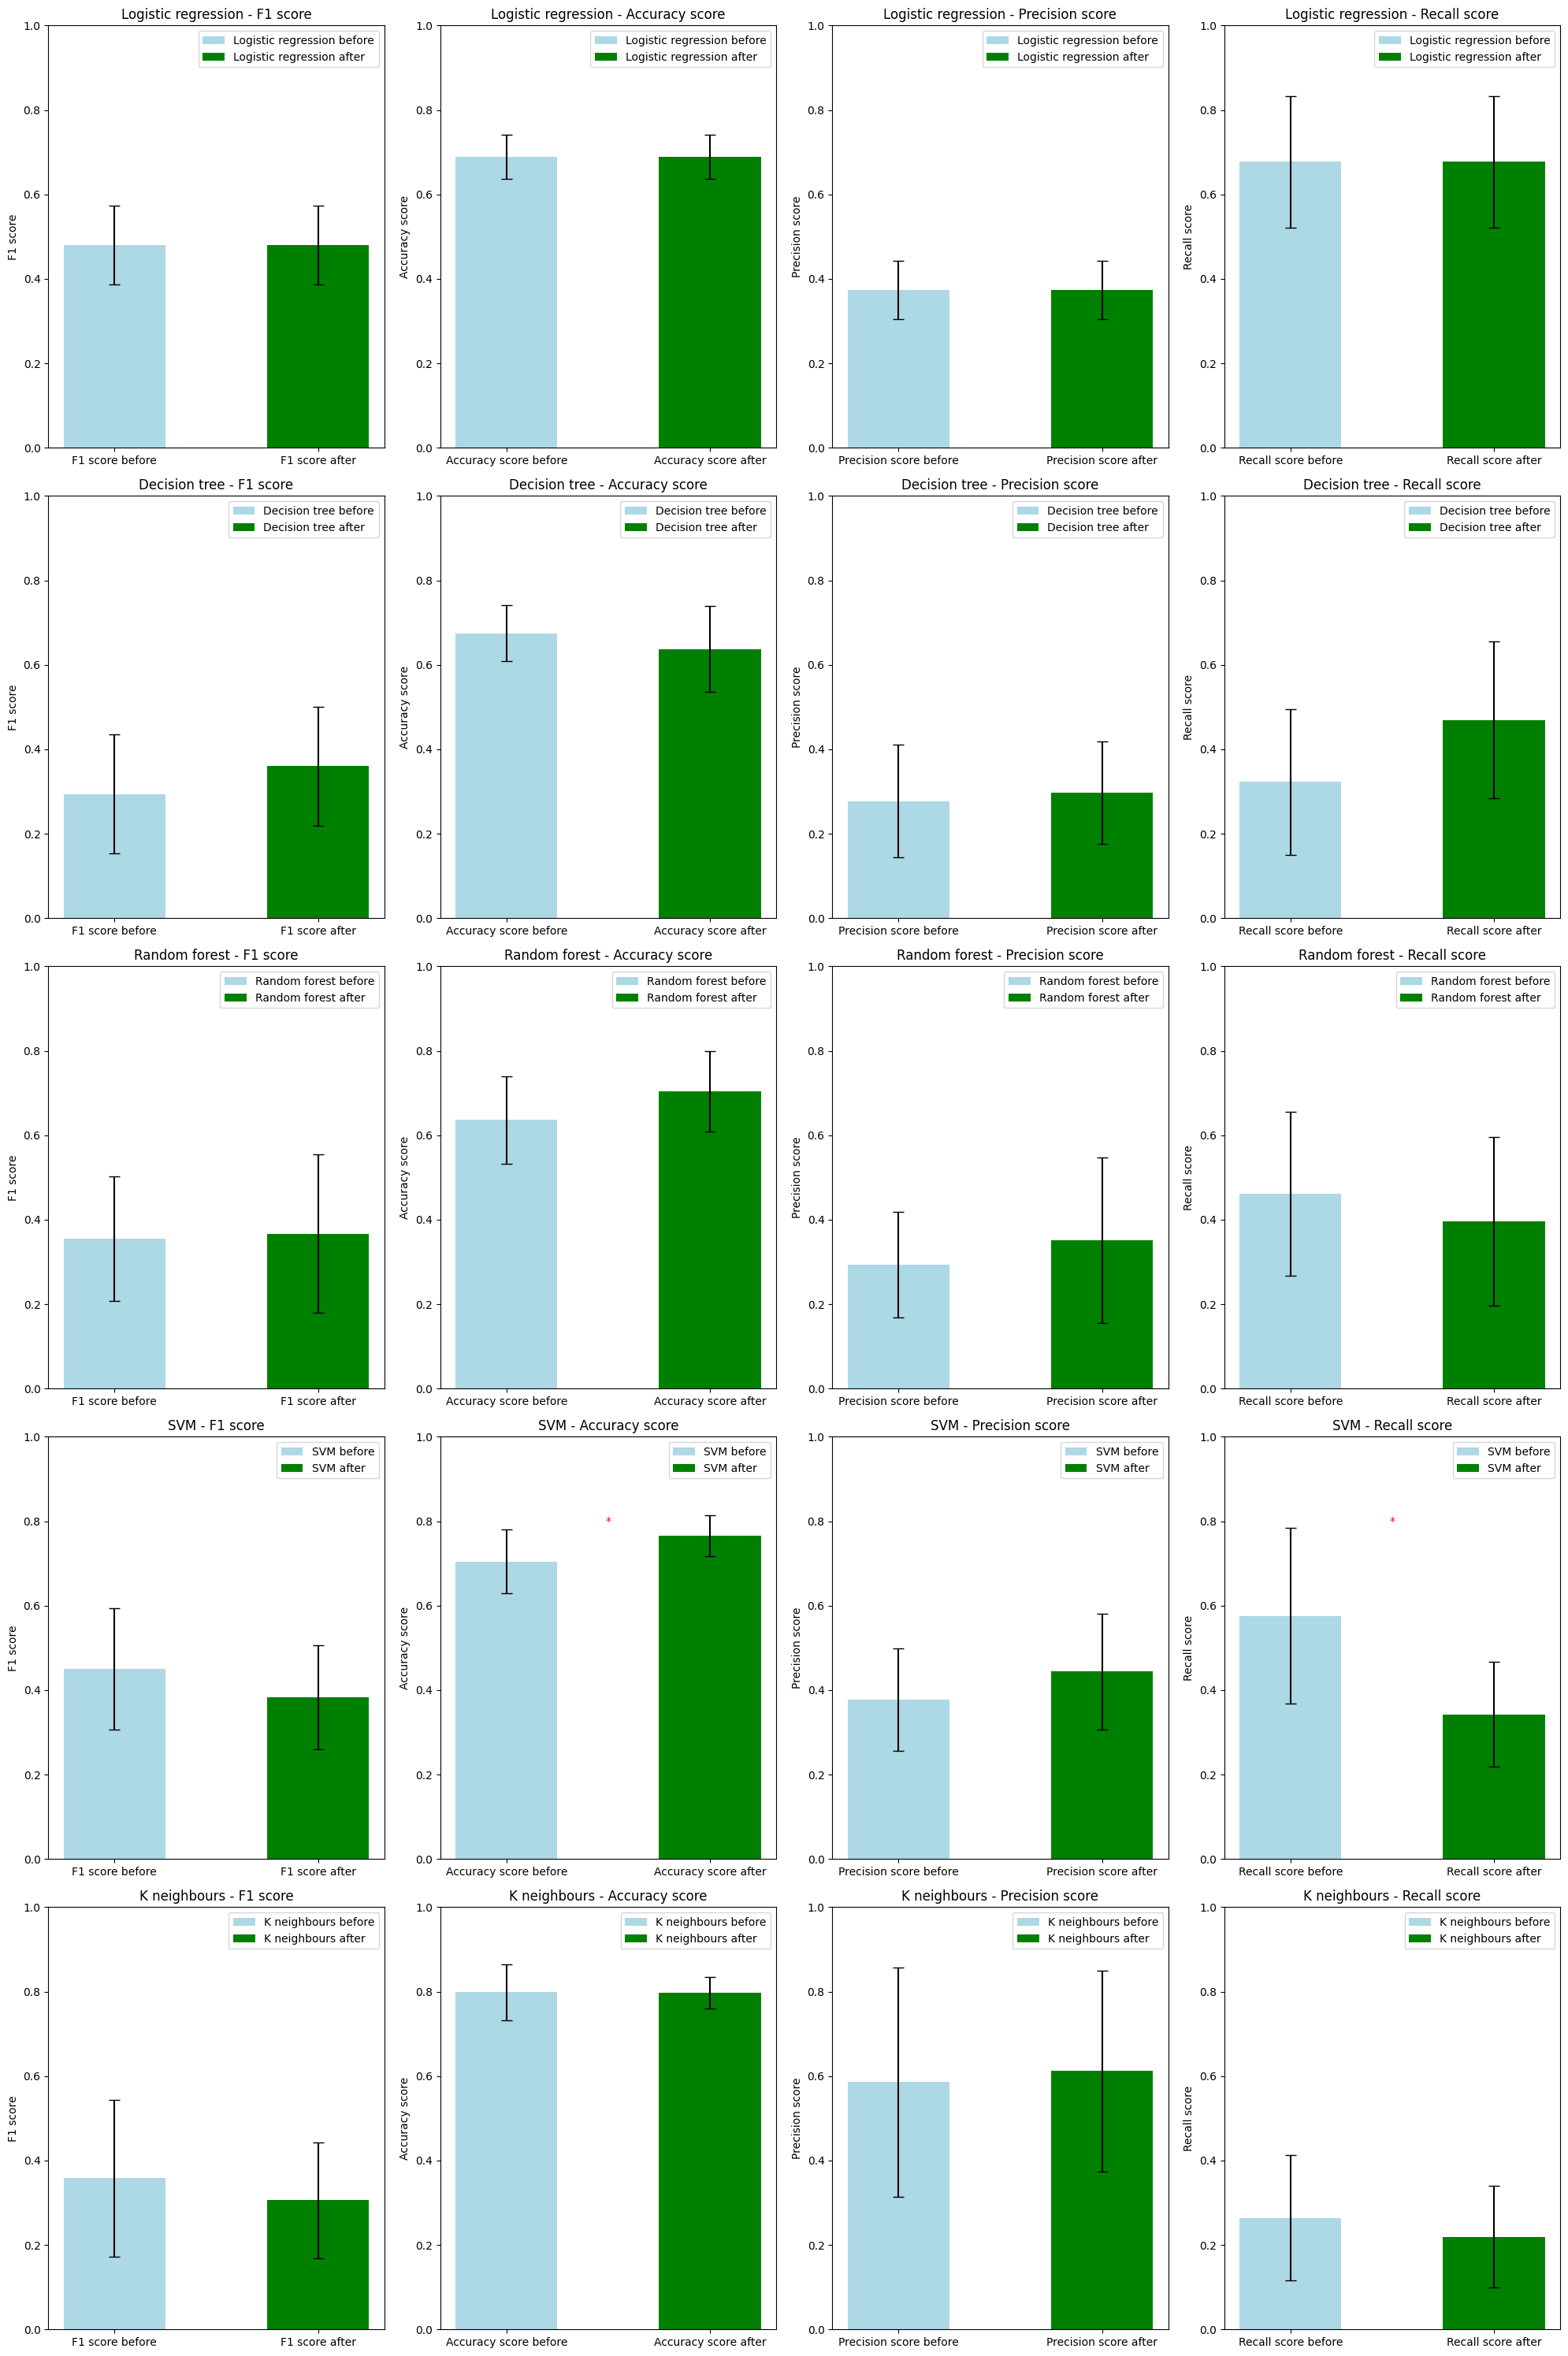

In [13]:

def modelBarcharts():
    keys = [1,2,3,4,5]
    algorithmName = ["Logistic regression", "Decision tree","Random forest","SVM", "K neighbours"]
    columnNames=['F1 score','Accuracy score','Precision score', 'Recall score']

    fig, axs = plt.subplots(len(keys), 4, figsize=(20, 30)) 
    # fig.suptitle('Model performance scores before and after Hyperparameter tuning')

    for i, key in enumerate(algorithmName):
        for j in range(4):
            df1 = before[i]
            df2 = after[key]
            value_column = columnNames[j]

            mean1 = df1[value_column].mean()
            mean2 = df2[value_column].mean()
            std1 = df1[value_column].std()
            std2 = df2[value_column].std()

            p = stats.ttest_ind(df1[value_column], df2[value_column]).pvalue
            if (p < 0.05):
                star = '*'
            else:
                star = ''

            positions = [1, 2] 
            axs[i, j].bar(positions[0], mean1, color='lightblue', yerr=std1, capsize=5, label=f'{key} before', width=0.5)
            axs[i, j].bar(positions[1], mean2, color='green', yerr=std2, capsize=5, label=f'{key} after', width=0.5)
            axs[i, j].set_xticks(positions)
            axs[i, j].set_xticklabels([f'{value_column} before', f'{value_column} after'])
            axs[i, j].set_ylabel(value_column)
            axs[i, j].legend()
            axs[i, j].set_title(f'{key} - {value_column}') 
            axs[i, j].set_ylim(0, 1)
            axs[i, j].text(1.5, 0.8, star, ha='center', va='center', color='red')
            
    plt.tight_layout() 
    plt.show()


modelBarcharts()